# 01 — Qualidade dos dados e EDA
Entendimento das quatro bases, qualidade, integridade, o papel de `versao_parcela`, distribuições, volume por safra e **PSI treino × submissão**.
As análises bivariadas com o target ficam no nb02. A limpeza reutilizável está em `src/data_loader.py`.

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
import data_loader as dl
from config import DADOS, OUTPUTS, DATA_OBSERVACAO
from evaluate import psi

pd.set_option('display.width', 200, 'display.max_columns', 60, 'display.max_rows', 100)
sns.set_theme(style='whitegrid')
OBS = pd.Timestamp(DATA_OBSERVACAO)
FIG, TAB = OUTPUTS / 'figures', OUTPUTS / 'tables'

NOMES = ['base_cadastral', 'base_submissao', 'historico_emprestimos', 'historico_parcelas']
raw = {n: pd.read_parquet(DADOS / f'{n}.parquet') for n in NOMES}
cad, sub, emp, par = dl.carregar_cadastral(), dl.carregar_submissao(), dl.carregar_emprestimos(), dl.carregar_parcelas()
bases = dict(zip(NOMES, [cad, sub, emp, par]))

## 1. Qualidade
### 1.1 Perfil das bases (já limpas): shape, tipos, nulos e cardinalidade

In [2]:
def perfil(df):
    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'nulos_%': (df.isna().mean() * 100).round(1), 'cardinalidade': df.nunique()})

perfis = []
for n, d in bases.items():
    p = perfil(d); p.insert(0, 'base', n); perfis.append(p)
    print(f'\n{n}: {d.shape[0]:,} linhas x {d.shape[1]} colunas'); display(p.drop(columns='base'))
pd.concat(perfis).to_csv(TAB / 'nb01_perfil_bases.csv')


base_cadastral: 50,000 linhas x 16 colunas


,dtype,nulos_%,cardinalidade
id_cliente,int64,0.0,50000
sexo,str,0.0,3
data_nascimento,datetime64[us],0.1,16101
qtd_filhos,int64,0.0,12
qtd_membros_familia,float64,0.0,13
renda_anual,float64,0.3,1645
tipo_renda,str,0.0,10
ocupacao,str,31.0,18
tipo_organizacao,str,0.0,58
nivel_educacao,str,0.0,5



base_submissao: 50,000 linhas x 8 colunas


,dtype,nulos_%,cardinalidade
id_cliente,int64,0.0,50000
data_solicitacao,datetime64[us],0.2,21
dia_semana_solicitacao,str,0.0,7
hora_solicitacao,str,0.0,31324
tipo_contrato,str,0.0,3
valor_credito,float64,0.0,5263
valor_bem,float64,4.9,2464
valor_parcela,float64,0.0,16976



historico_emprestimos: 211,944 linhas x 37 colunas


,dtype,nulos_%,cardinalidade
id_contrato,int64,0.0,211944
id_cliente,int64,0.0,47952
tipo_contrato,str,0.0,3
status_contrato,str,0.0,4
data_decisao,datetime64[us],0.0,2955
data_liberacao,datetime64[us],96.4,2303
data_primeiro_vencimento,datetime64[us],42.1,2925
data_ultimo_vencimento_original,datetime64[us],44.9,4509
data_ultimo_vencimento,datetime64[us],54.3,2828
data_encerramento,datetime64[us],55.1,2612



historico_parcelas: 1,659,408 linhas x 8 colunas


,dtype,nulos_%,cardinalidade
id_contrato,int64,0.0,122867
id_cliente,int64,0.0,46231
versao_parcela,float64,0.0,52
numero_parcela,int64,0.0,193
data_prevista_pagamento,datetime64[us],0.0,2910
data_real_pagamento,datetime64[us],0.2,2923
valor_previsto_parcela,float64,0.0,251978
valor_pago_parcela,float64,0.2,390601


### 1.2 Duplicatas por chave (dados brutos × após limpeza)

In [3]:
K_PAR = ['id_contrato', 'numero_parcela', 'versao_parcela']
dup = pd.DataFrame([
    ('cadastral: id_cliente', len(raw['base_cadastral']), raw['base_cadastral'].id_cliente.duplicated().sum(), cad.id_cliente.duplicated().sum()),
    ('submissão: id_cliente', len(raw['base_submissao']), raw['base_submissao'].id_cliente.duplicated().sum(), sub.id_cliente.duplicated().sum()),
    ('empréstimos: id_contrato', len(raw['historico_emprestimos']), raw['historico_emprestimos'].id_contrato.duplicated().sum(), emp.id_contrato.duplicated().sum()),
    ('parcelas: linhas idênticas', len(raw['historico_parcelas']), raw['historico_parcelas'].duplicated().sum(), par.duplicated().sum()),
    ('parcelas: (contrato, parcela, versão) repetida', len(raw['historico_parcelas']), raw['historico_parcelas'].duplicated(K_PAR).sum(), par.duplicated(K_PAR).sum()),
], columns=['chave', 'linhas_brutas', 'repetidas_brutas', 'repetidas_apos_limpeza'])
display(dup)

,chave,linhas_brutas,repetidas_brutas,repetidas_apos_limpeza
0,cadastral: id_cliente,50600,600,0
1,submissão: id_cliente,50400,400,0
2,empréstimos: id_contrato,211944,0,0
3,parcelas: linhas idênticas,1664384,4976,0
4,"parcelas: (contrato, parcela, versão) repetida",1664384,79945,74969


- **Cadastral e submissão:** a 2ª cópia (sempre no fim do arquivo) tem valores alterados (renda, hora, valor do crédito). Mantemos a **1ª ocorrência**.
- **Parcelas:** as linhas idênticas são removidas. A chave (contrato, parcela, versão) ainda se repete, porque uma parcela pode ter **pagamentos parciais** (várias linhas) — ver seção 2.

### 1.3 Tipagem e categorias

In [4]:
bruto, limpo = raw['base_cadastral'], cad
print('renda_anual (texto) — formatos distintos:', bruto.renda_anual.str.replace(r'\d', '9', regex=True).value_counts().head(8).to_dict())
print('renda_anual (limpa): nulos =', limpo.renda_anual.isna().sum(), '(inclui "não informado" e renda negativa)')
print('\ndata_solicitacao inválidas na submissão:', raw['base_submissao'].data_solicitacao[~raw['base_submissao'].data_solicitacao.str.match(r'^\d{4}-(0[1-9]|1[0-2])-\d{2}$')].value_counts().to_dict(), '-> NaT')
var = pd.DataFrame({
    'categorias_antes': [raw[n][c].nunique() for n, c in [('base_cadastral', 'sexo'), ('base_cadastral', 'possui_carro'), ('base_submissao', 'dia_semana_solicitacao'), ('base_submissao', 'tipo_contrato'), ('historico_emprestimos', 'tipo_contrato')]],
    'categorias_depois': [cad.sexo.nunique(), cad.possui_carro.nunique(), sub.dia_semana_solicitacao.nunique(), sub.tipo_contrato.nunique(), emp.tipo_contrato.nunique()],
}, index=['cad.sexo', 'cad.possui_carro', 'sub.dia_semana', 'sub.tipo_contrato', 'emp.tipo_contrato'])
display(var)
# Checagem de grafia nas demais colunas de texto: sobrou alguma chave com mais de uma forma?
resid = {f'{n}.{c}': int(d[c].dropna().map(dl._chave).nunique() != d[c].nunique())
         for n, d in bases.items() for c in d.select_dtypes('string').columns if d[c].nunique() <= 100}
print('colunas de texto ainda com variantes de grafia:', [k for k, v in resid.items() if v] or 'nenhuma')

renda_anual (texto) — formatos distintos: {'999.999,99': 39577, '99.999,99': 10485, 'não informado': 101, 'R$ 999.999,99': 80, '999999,99': 80, '9,99': 67, '-99.999,99': 62, '99.999.999,99': 60}
renda_anual (limpa): nulos = 164 (inclui "não informado" e renda negativa)

data_solicitacao inválidas na submissão: {'2025-13-01': 51, '24/02/2025': 50} -> NaT


,categorias_antes,categorias_depois
cad.sexo,6,3
cad.possui_carro,7,3
sub.dia_semana,10,7
sub.tipo_contrato,6,3
emp.tipo_contrato,6,3


colunas de texto ainda com variantes de grafia: nenhuma


### 1.4 Integridade referencial (cold start incluído)

In [5]:
ids = {n: set(d.id_cliente) for n, d in [('cad', cad), ('sub', sub), ('emp', emp), ('par', par)]}
aprov = emp[emp.status_contrato == 'Aprovado']
integr = pd.Series({
    'clientes da submissão ausentes no cadastro': len(ids['sub'] - ids['cad']),
    'clientes de empréstimos ausentes no cadastro': len(ids['emp'] - ids['cad']),
    'contratos de parcelas ausentes em empréstimos': len(set(par.id_contrato) - set(emp.id_contrato)),
    'parcelas de contratos não aprovados': int((~par.id_contrato.isin(aprov.id_contrato)).sum()),
    'clientes da submissão sem histórico de empréstimos (cold start)': len(ids['sub'] - ids['emp']),
    'clientes da submissão sem nenhum contrato com parcelas': len(ids['sub'] - ids['par']),
    'aprovados com parcelas': int(aprov.id_contrato.isin(par.id_contrato).sum()),
    'aprovados sem parcelas': int((~aprov.id_contrato.isin(par.id_contrato)).sum()),
}).to_frame('n'); display(integr)

,n
clientes da submissão ausentes no cadastro,0
clientes de empréstimos ausentes no cadastro,0
contratos de parcelas ausentes em empréstimos,0
parcelas de contratos não aprovados,0
clientes da submissão sem histórico de empréstimos (cold start),2048
clientes da submissão sem nenhum contrato com parcelas,3769
aprovados com parcelas,122867
aprovados sem parcelas,8868


Aprovados sem parcelas são, em geral, contratos recentes (primeira parcela ainda não venceu na data de observação):

In [6]:
a = aprov.assign(ano=aprov.data_decisao.dt.year, tem_parcelas=aprov.id_contrato.isin(par.id_contrato))
display(a.groupby('ano').tem_parcelas.agg(aprovados='size', pct_com_parcelas='mean').round(3).T)

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025
aprovados,6850.000,10818.000,10058.000,11301.000,13869.000,21235.000,29841.000,26056.000,1707.000
pct_com_parcelas,0.978,0.979,0.981,0.983,0.961,0.951,0.929,0.879,0.264


### 1.5 Colunas reais × dicionário

In [7]:
dic = pd.read_excel(DADOS.parent / 'dicionario_dados.xlsx')
dic.columns = ['base', 'coluna', 'descricao']
rows = []
for n, d in zip(NOMES, [cad, sub, emp, par]):
    esperado, real = set(dic[dic.base == n].coluna), set(d.columns)
    rows.append((n, sorted(esperado - real) or '—', sorted(real - esperado) or '—'))
display(pd.DataFrame(rows, columns=['base', 'no dicionário e ausente nos dados', 'nos dados e ausente no dicionário']))

,base,no dicionário e ausente nos dados,nos dados e ausente no dicionário
0,base_cadastral,—,—
1,base_submissao,—,—
2,historico_emprestimos,"[flag_seguro_contratado, flag_ultima_solicitac...","[indicador_seguro_contratado, indicador_ultima..."
3,historico_parcelas,—,—


Divergência apenas de nomes (`flag_*` no dicionário, `indicador_*` nos dados); nenhuma dessas colunas é feature. A descrição de `valor_credito` no dicionário repete a de `valor_solicitado` (provável erro de cópia).

## 2. `versao_parcela`: o que ela representa?
O plano pede verificar se a versão nova indica **renegociação** (vencimento muda) ou outro fenômeno. O resultado define como consolidar a parcela no target.

In [8]:
K = ['id_contrato', 'numero_parcela']
g = par.groupby(K)
par['n_versoes'] = g.versao_parcela.transform('nunique')
par['n_linhas'] = g.versao_parcela.transform('size')
print('parcelas por nº de versões:', par.drop_duplicates(K).n_versoes.value_counts().sort_index().to_dict())
mv = par[par.n_versoes > 1]; gm = mv.groupby(K)
x = gm.agg(prev=('valor_previsto_parcela', 'sum'), pago=('valor_pago_parcela', 'first'))
res = pd.Series({
    'parcelas com >1 versão': gm.ngroups,
    '% com mesmo vencimento entre versões': (gm.data_prevista_pagamento.nunique() == 1).mean(),
    '% com mesma data de pagamento entre versões': (gm.data_real_pagamento.nunique() == 1).mean(),
    '% com mesmo valor pago em todas as versões': (gm.valor_pago_parcela.nunique() == 1).mean(),
    '% em que soma(previsto das versões) ≈ pago (±1%)': ((x.prev - x.pago).abs() <= 0.01 * x.pago).mean(),
    '% em que o previsto de UMA versão já cobre o pago': (gm.valor_previsto_parcela.max() >= x.pago - 0.01).mean(),
}).round(3).to_frame('valor'); display(res)
print('\nExemplo (versões de uma mesma parcela):')
ex = mv.sort_values(K + ['versao_parcela']).head(2)[['id_contrato', 'numero_parcela', 'versao_parcela', 'data_prevista_pagamento', 'data_real_pagamento', 'valor_previsto_parcela', 'valor_pago_parcela']]
display(ex)

parcelas por nº de versões: {1: 1564388, 2: 10018, 3: 5}


,valor
parcelas com >1 versão,10023.000
% com mesmo vencimento entre versões,0.997
% com mesma data de pagamento entre versões,0.986
% com mesmo valor pago em todas as versões,0.978
% em que soma(previsto das versões) ≈ pago (±1%),0.984
% em que o previsto de UMA versão já cobre o pago,0.006



Exemplo (versões de uma mesma parcela):


,id_contrato,numero_parcela,versao_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
1283320,1000081,2,1.0,2024-02-26,2024-02-07,22021.47,225000.0
1283319,1000081,2,2.0,2024-02-26,2024-02-07,202978.53,225000.0


In [9]:
# Pagamentos parciais: várias linhas na MESMA versão (previsto repetido, pagos distintos)
mr = par[(par.n_versoes == 1) & (par.n_linhas > 1)]
y = mr.groupby(K).agg(prev=('valor_previsto_parcela', 'first'), pago=('valor_pago_parcela', 'sum'))
print(f'parcelas com pagamentos parciais: {len(y):,} | soma dos pagamentos ≥ previsto: {(y.pago >= y.prev - 0.01).mean():.1%}')
# Uma parcela sem pagamento só existe se já venceu
np_ = par[par.valor_pago_parcela.isna()]
print(f'parcelas sem pagamento: {len(np_):,} | todas vencidas até a observação: {(np_.data_prevista_pagamento <= OBS).all()}')

parcelas com pagamentos parciais: 73,043 | soma dos pagamentos ≥ previsto: 99.6%
parcelas sem pagamento: 3,625 | todas vencidas até a observação: True


**Conclusão (a registrar em `docs/DECISOES.md`):**
- O **vencimento não muda** entre versões; a versão **não é renegociação**: é o **fracionamento** da parcela (o previsto é dividido entre as versões e a soma bate com o pago).
- O valor **pago aparece repetido** em cada versão. Somar o pago linha a linha dobraria o pagamento; usar o previsto de uma só versão faria a parcela parecer paga a mais.
- Regra de consolidação (no `features.py`): **previsto = soma dos previstos das versões**; **pago = valor pago de uma versão só** (somando pagamentos parciais dentro da versão); **vencimento = `data_prevista_pagamento`**.

## 3. EDA univariada e temporal
### 3.1 Numéricas e outliers (IQR 1,5× e percentis)

In [10]:
def outliers(df, cols):
    r = {}
    for c in cols:
        s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        r[c] = {'n': len(s), 'min': s.min(), 'mediana': s.median(), 'p99': s.quantile(.99), 'max': s.max(),
                '% fora IQR': ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100, 'max / p99': s.max() / s.quantile(.99)}
    return pd.DataFrame(r).T.round(2)

print('Cadastral'); display(outliers(cad, ['renda_anual', 'qtd_filhos', 'qtd_membros_familia']))
print('Submissão'); display(outliers(sub, ['valor_credito', 'valor_bem', 'valor_parcela']))
aprov_p = emp[(emp.status_contrato == 'Aprovado') & emp.id_contrato.isin(par.id_contrato)]
print('Empréstimos aprovados com parcelas (base de treino)'); display(outliers(aprov_p, ['valor_credito', 'valor_bem', 'valor_parcela']))

Cadastral


,n,min,mediana,p99,max,% fora IQR,max / p99
renda_anual,49836.0,0.0,148500.0,540000.0,117000000.0,5.21,216.67
qtd_filhos,50000.0,0.0,0.0,3.0,14.0,2.80,4.67
qtd_membros_familia,50000.0,0.0,2.0,5.0,15.0,2.86,3.00


Submissão


,n,min,mediana,p99,max,% fora IQR,max / p99
valor_credito,50000.0,15000.0,450000.0,1864223.28,135000000.0,2.93,72.42
valor_bem,47556.0,12425.0,450000.0,1800000.00,4050000.0,2.85,2.25
valor_parcela,49996.0,0.0,23049.0,76161.38,302580.5,2.88,3.97


Empréstimos aprovados com parcelas (base de treino)


,n,min,mediana,p99,max,% fora IQR,max / p99
valor_credito,122867.0,0.0,97483.50,1345311.00,3524220.00,10.48,2.62
valor_bem,115361.0,0.0,93442.50,1264004.62,3150000.00,11.40,2.49
valor_parcela,122866.0,0.0,9776.56,74575.22,474981.77,7.40,6.37


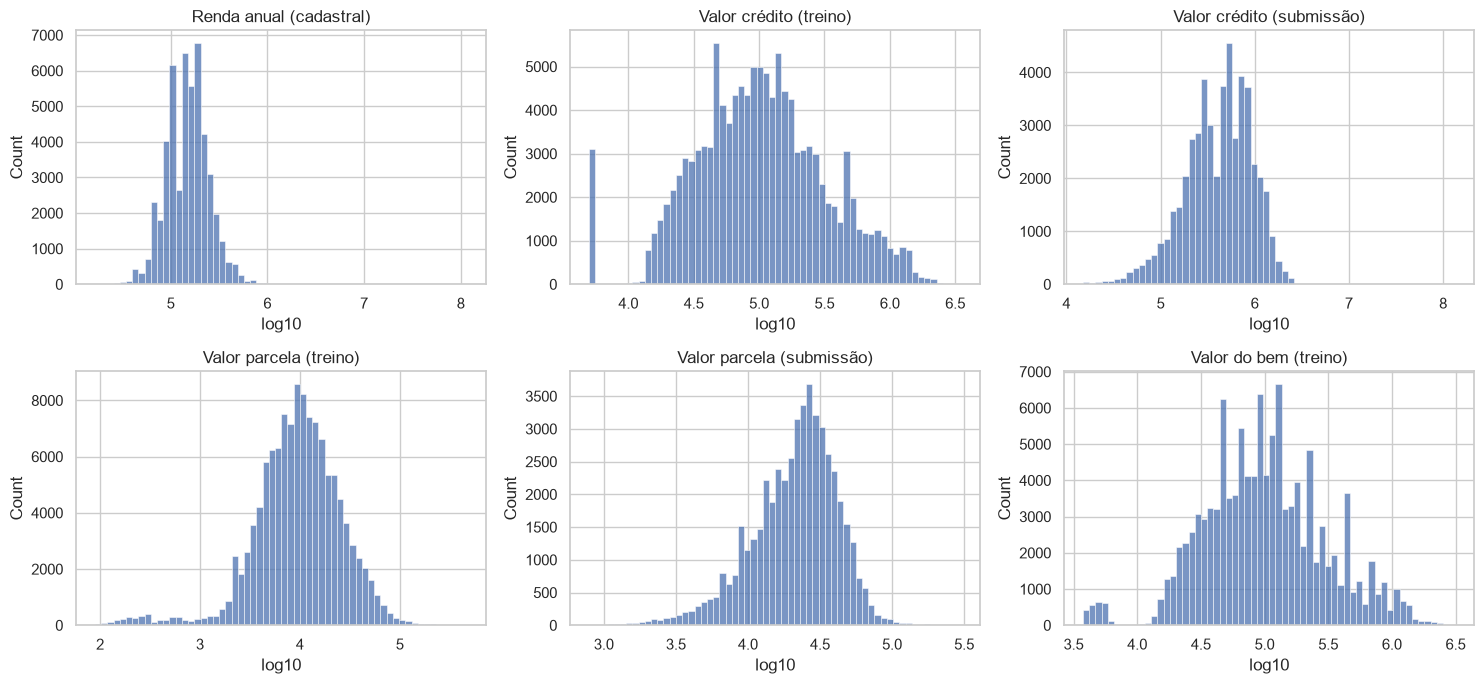

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, (df, c, t) in zip(ax.ravel(), [(cad, 'renda_anual', 'Renda anual (cadastral)'), (aprov_p, 'valor_credito', 'Valor crédito (treino)'), (sub, 'valor_credito', 'Valor crédito (submissão)'),
                                      (aprov_p, 'valor_parcela', 'Valor parcela (treino)'), (sub, 'valor_parcela', 'Valor parcela (submissão)'), (aprov_p, 'valor_bem', 'Valor do bem (treino)')]):
    sns.histplot(np.log10(df[c][df[c] > 0]), bins=60, ax=a); a.set_title(t); a.set_xlabel('log10')
plt.tight_layout(); plt.savefig(FIG / 'nb01_distribuicoes.png', dpi=110); plt.show()

Há **cauda extrema** em `renda_anual` e `valor_credito` (máximo muito acima do p99), provável erro de digitação/escala. **Nenhum tratamento aqui**; a decisão (manter, winsorizar ou limitar) é discutida com o usuário após ver o impacto no nb02/nb03 (modelos de árvore são robustos a outliers; a regressão logística baseline não).

### 3.2 Categóricas

In [12]:
for n, d, cols in [('cadastral', cad, ['sexo', 'tipo_renda', 'estado_civil', 'nivel_educacao', 'tipo_moradia', 'nota_regiao_cliente']),
                   ('submissão', sub, ['tipo_contrato', 'dia_semana_solicitacao'])]:
    print(n)
    for c in cols: print(f'  {c}:', (d[c].value_counts(normalize=True, dropna=False) * 100).round(1).to_dict())
print('\nocupacao nulos (cadastral):', f'{cad.ocupacao.isna().mean():.1%}', '| valor_bem nulo (submissão):', f'{sub.valor_bem.isna().mean():.1%}')

cadastral
  sexo: {'Feminino': 64.9, 'Masculino': 35.0, 'Não informado': 0.1}
  tipo_renda: {'Assalariado': 50.6, 'Associado comercial': 22.9, 'Aposentado': 18.3, 'Servidor público': 7.3, 'Autônomo': 0.8, 'Não informado': 0.1, 'Desempregado': 0.0, 'Licença maternidade': 0.0, 'Estudante': 0.0, 'Empresário': 0.0}
  estado_civil: {'Casado': 63.5, 'Solteiro': 15.1, 'União estável': 9.8, 'Separado': 6.5, 'Viúvo': 5.1}
  nivel_educacao: {'Ensino médio': 70.7, 'Ensino superior': 24.3, 'Ensino superior incompleto': 3.5, 'Ensino fundamental': 1.4, 'Pós-graduação': 0.2}
  tipo_moradia: {'Casa ou apartamento': 88.5, 'Mora com os pais': 4.9, 'Apartamento municipal': 3.5, 'Imóvel alugado': 1.9, 'Apartamento funcional': 0.9, 'Apartamento cooperativo': 0.4}
  nota_regiao_cliente: {2: 70.2, 3: 19.1, 1: 10.7}
submissão
  tipo_contrato: {'Empréstimo em dinheiro': 40.0, 'Financiamento de consumo': 36.0, 'Crédito rotativo': 24.0}
  dia_semana_solicitacao: {'terça-feira': 17.4, 'quarta-feira': 16.3, 'quint

### 3.3 Volume por safra (mês da decisão)

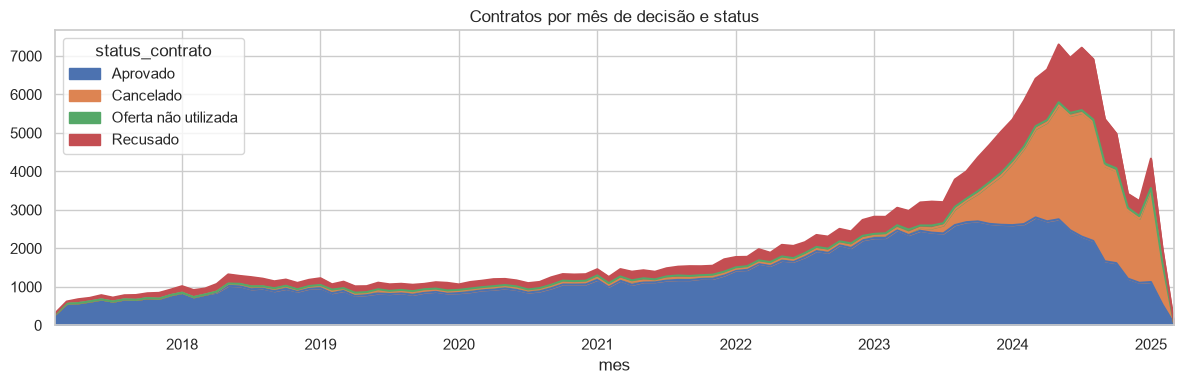

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025
contratos,7986.000,13639.000,13049.000,14356.000,17721.000,26061.000,43135.000,69610.000,6387.000
pct_aprovado,0.858,0.793,0.771,0.787,0.783,0.815,0.692,0.374,0.267


Submissão por dia de solicitação: 2025-02-04 a 2025-02-24 | clientes: 50000


In [13]:
e = emp.assign(mes=emp.data_decisao.dt.to_period('M').dt.to_timestamp())
vol = e.groupby(['mes', 'status_contrato']).size().unstack(fill_value=0)
vol['com_parcelas_aprovados'] = e[e.id_contrato.isin(par.id_contrato)].groupby('mes').size()
ax = vol.drop(columns='com_parcelas_aprovados').plot.area(figsize=(12, 4), title='Contratos por mês de decisão e status'); plt.tight_layout()
plt.savefig(FIG / 'nb01_volume_safra.png', dpi=110); plt.show()
anual = e.assign(ano=e.mes.dt.year).groupby('ano').agg(contratos=('id_contrato', 'size'), pct_aprovado=('status_contrato', lambda s: (s == 'Aprovado').mean()))
display(anual.round(3).T)
print('Submissão por dia de solicitação:', sub.data_solicitacao.min().date(), 'a', sub.data_solicitacao.max().date(), '| clientes:', len(sub))

### 3.4 Data de observação
A data de observação do target é a **última data observada** nas parcelas (todas as parcelas do arquivo vencem até ela).

In [14]:
print('máx. data_real_pagamento :', par.data_real_pagamento.max().date())
print('máx. data_prevista_pagamento:', par.data_prevista_pagamento.max().date())
print('máx. data_solicitacao (submissão):', sub.data_solicitacao.max().date())
print('data_decisao em empréstimos > observação:', int((emp.data_decisao > OBS).sum()), 'contratos (fora do alcance das parcelas)')
print('DATA_OBSERVACAO em config.py =', DATA_OBSERVACAO)

máx. data_real_pagamento : 2025-02-22
máx. data_prevista_pagamento: 2025-02-22
máx. data_solicitacao (submissão): 2025-02-24
data_decisao em empréstimos > observação: 134 contratos (fora do alcance das parcelas)
DATA_OBSERVACAO em config.py = 2025-02-22


## 4. PSI: população de treino × submissão
- **Treino:** contratos aprovados com parcelas, com o cadastro do cliente.
- **Submissão:** o contrato mais recente de cada cliente, com o cadastro.
- Limiar usual: < 0,10 estável; 0,10–0,25 atenção; > 0,25 mudança relevante (candidata a sair, conforme o plano).

In [15]:
def monta(contratos):
    d = contratos.merge(cad, on='id_cliente', how='left', suffixes=('', '_cad'))
    d['hora'] = pd.to_datetime(d.hora_solicitacao, format='%H:%M:%S', errors='coerce').dt.hour
    d['idade'] = (OBS - d.data_nascimento).dt.days / 365.25
    return d

CONTRATO = ['tipo_contrato', 'valor_credito', 'valor_bem', 'valor_parcela', 'dia_semana_solicitacao', 'hora']
CADASTRO = ['sexo', 'idade', 'qtd_filhos', 'qtd_membros_familia', 'renda_anual', 'tipo_renda', 'ocupacao', 'tipo_organizacao', 'nivel_educacao',
            'estado_civil', 'tipo_moradia', 'possui_carro', 'possui_imovel', 'nota_regiao_cliente', 'nota_regiao_cliente_cidade']
tr, sb = monta(aprov_p), monta(sub)
tab = pd.DataFrame({c: {'grupo': 'contrato' if c in CONTRATO else 'cadastro', 'PSI': psi(tr[c], sb[c])} for c in CONTRATO + CADASTRO}).T
tab['PSI'] = tab.PSI.astype(float).round(4)
tab['leitura'] = pd.cut(tab.PSI, [-1, .10, .25, np.inf], labels=['estável', 'atenção', 'mudança relevante'])
tab = tab.sort_values('PSI', ascending=False); tab.to_csv(TAB / 'nb01_psi_treino_submissao.csv'); display(tab)

,grupo,PSI,leitura
valor_bem,contrato,2.4600,mudança relevante
valor_credito,contrato,1.9647,mudança relevante
valor_parcela,contrato,0.9538,mudança relevante
dia_semana_solicitacao,contrato,0.0485,estável
hora,contrato,0.0225,estável
idade,cadastro,0.0055,estável
nivel_educacao,cadastro,0.0038,estável
tipo_organizacao,cadastro,0.0037,estável
ocupacao,cadastro,0.0030,estável
renda_anual,cadastro,0.0029,estável


**Leitura:** as variáveis de cadastro e `tipo_contrato`, `dia_semana`, `hora` são **estáveis** (PSI < 0,05). As três variáveis de **valor** (`valor_bem`, `valor_credito`, `valor_parcela`) têm PSI entre 0,95 e 2,46: a submissão está fora da distribuição do treino. Investigação abaixo.

### 4.1 Investigação: por que os valores mudam?

In [16]:
r = aprov_p.merge(cad[['id_cliente', 'renda_anual']], on='id_cliente'); s = sub.merge(cad[['id_cliente', 'renda_anual']], on='id_cliente')
def rel(d):
    d = d.assign(credito_bem=d.valor_credito / d.valor_bem, parcela_credito=d.valor_parcela / d.valor_credito, credito_renda=d.valor_credito / d.renda_anual)
    return d.replace([np.inf, -np.inf], np.nan)
r, s = rel(r), rel(s)
cols = ['valor_credito', 'valor_bem', 'valor_parcela', 'credito_bem', 'parcela_credito', 'credito_renda']
q = pd.concat({'treino (aprov. c/ parcelas)': r[cols].median(), 'treino >= 2024-07': r[r.data_decisao >= '2024-07-01'][cols].median(), 'submissão': s[cols].median()}, axis=1)
q['submissão / treino'] = q['submissão'] / q['treino (aprov. c/ parcelas)']; display(q.round(2))
print('PSI das razões (treino × submissão):', {c: round(psi(r[c], s[c]), 2) for c in ['credito_bem', 'parcela_credito', 'credito_renda']})
print('PSI valor_credito (treino >= 2024-07 × submissão):', round(psi(r[r.data_decisao >= '2024-07-01'].valor_credito, s.valor_credito), 2))
tempo = r.groupby(r.data_decisao.dt.year).agg(valor_credito=('valor_credito', 'median'), credito_renda=('credito_renda', 'median'), n=('id_contrato', 'size'))
display(tempo.round(2).T)

,treino (aprov. c/ parcelas),treino >= 2024-07,submissão,submissão / treino
valor_credito,97483.50,107325.00,450000.00,4.62
valor_bem,93442.50,106287.75,450000.00,4.82
valor_parcela,9776.56,10787.26,23049.00,2.36
credito_bem,1.00,1.01,1.11,1.11
parcela_credito,0.10,0.10,0.05,0.49
credito_renda,0.66,0.73,2.83,4.30


PSI das razões (treino × submissão): {'credito_bem': 0.63, 'parcela_credito': 1.43, 'credito_renda': 2.13}
PSI valor_credito (treino >= 2024-07 × submissão): 1.69


data_decisao,2017,2018,2019,2020,2021,2022,2023,2024,2025
valor_credito,45164.25,53491.50,54220.50,71955.00,95600.25,135585.00,136777.50,118764.00,97814.42
credito_renda,0.31,0.37,0.37,0.47,0.64,0.91,0.95,0.82,0.64
n,6702.00,10589.00,9865.00,11110.00,13324.00,20205.00,27709.00,22913.00,450.00


**Conclusão:**
1. Mesmo no cadastro (renda) os clientes são os mesmos; só os **valores do contrato** mudam. A mediana de `valor_credito` é 450 mil na submissão contra 97 mil no treino (4,6×) e 101 mil nos aprovados de 2025.
2. Não é só um fator multiplicativo: as **razões** (crédito/bem, parcela/crédito, crédito/renda) também têm PSI alto (0,6–2,1), e a razão crédito/renda mediana é 2,83 na submissão e 0,66 no treino. O formato dos contratos da submissão é diferente (mais alto, prazo mais longo).
3. No treino, o valor mediano também **cresce com o tempo** (46 mil em 2017 → 141 mil em 2022).
4. Consequência: um modelo que usa `valor_*` colocaria praticamente toda a submissão nas faixas mais altas do treino; as probabilidades não seriam confiáveis. **Decisão pendente com o usuário** (ver `docs/DECISOES.md`).

### 4.2 Diagnóstico: os contratos da submissão estão no histórico? E em relação ao histórico do próprio cliente?

In [17]:
m = sub.merge(emp, on=['id_cliente', 'hora_solicitacao'], suffixes=('_s', '_e'))
print(f'contratos da submissão com par no histórico (cliente + hora): {len(m)} de {len(sub):,} (coincidência) -> a submissão NÃO está no histórico')
hist = emp[emp.status_contrato == 'Aprovado'].groupby('id_cliente').valor_credito.median().rename('hist_med')
razao = (sub.merge(hist, on='id_cliente').eval('valor_credito / hist_med')).replace([np.inf, -np.inf], np.nan).dropna()
print('valor_credito da submissão / mediana dos aprovados do próprio cliente:', razao.quantile([.1, .25, .5, .75, .9]).round(2).to_dict())
rec = emp[emp.data_decisao >= '2024-07-01']
print('mediana de valor_credito por status (decisões a partir de 2024-07):'); display(rec.groupby('status_contrato').valor_credito.agg(['size', 'median']).round(0))

contratos da submissão com par no histórico (cliente + hora): 9 de 50,000 (coincidência) -> a submissão NÃO está no histórico
valor_credito da submissão / mediana dos aprovados do próprio cliente: {0.1: 0.93, 0.25: 1.88, 0.5: 4.02, 0.75: 8.49, 0.9: 16.63}
mediana de valor_credito por status (decisões a partir de 2024-07):


,size,median
status_contrato,,
Aprovado,11799,108072.0
Cancelado,18080,0.0
Oferta não utilizada,483,69682.0
Recusado,7142,303626.0


- O histórico do próprio cliente confirma um **nível ~4× maior** (mediana 4,0), mas **muito disperso** (P25 1,9; P75 8,5): não é um fator único que se possa dividir.
- Entre os contratos do histórico, os **recusados** têm valor mediano maior que os aprovados; se a submissão for composta por **solicitações** (antes da decisão), parte da diferença é de seleção, não de escala.